# Soybean price shocks and deforestation: exposure design

## 1. Data and outcome

In [1]:
import numpy as np
import pandas as pd

BASE = "https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/main/data/"
START_YEAR, END_YEAR = 2001, 2023  # DeDuCE coverage

In [2]:
# Load the 62-country GFW panel, DeDuCE commodity attribution and Pink Sheet prices
panel_raw = pd.read_csv(BASE + "processed/shock_panel.csv")
deduce = pd.read_csv(BASE + "processed/deduce_selected_commodities.csv")
prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")

# Soybeans price, kept for the next steps (one lag requires START_YEAR - 1)
soy_price = prices.loc[prices["commodity"] == "Soybeans", ["year", "price_real", "log_price_real"]]
soy_price_years = set(soy_price.dropna()["year"])
assert set(range(START_YEAR - 1, END_YEAR + 1)) <= soy_price_years

print("GFW panel:", panel_raw.shape, "| countries:", panel_raw["iso3"].nunique(),
      "| years:", panel_raw["year"].min(), "-", panel_raw["year"].max())
print("Soybeans price years:", soy_price["year"].min(), "-", soy_price["year"].max())

GFW panel: (1550, 13) | countries: 62 | years: 2001 - 2025
Soybeans price years: 1960 - 2025


In [3]:
# Restrict to the DeDuCE period and attach soybean deforestation on iso3 + year
panel = panel_raw[panel_raw["year"].between(START_YEAR, END_YEAR)].copy()
soy_defor = deduce.loc[deduce["commodity"] == "Soya beans", ["iso3", "year", "defor_ha"]]

df = panel.merge(soy_defor, on=["iso3", "year"], how="left", validate="one_to_one")

# Countries absent from the soybean rows of DeDuCE are coded as zero and flagged
df["in_deduce_soy"] = df["defor_ha"].notna()
df["defor_ha"] = df["defor_ha"].fillna(0.0)

assert df["iso3"].nunique() == 62
assert len(df) == 62 * (END_YEAR - START_YEAR + 1)
assert df["extent_2000_ha"].gt(0).all()

absent = df.loc[~df["in_deduce_soy"], ["iso3", "country", "region"]].drop_duplicates()
all_deduce_iso3 = set(deduce["iso3"])
assert set(absent["iso3"]) <= all_deduce_iso3  # present in DeDuCE for other commodities
print("Countries with no soybean rows in DeDuCE:", len(absent))
print(absent.sort_values(["region", "country"]).to_string(index=False))

Countries with no soybean rows in DeDuCE: 15
iso3                  country                    region
 CAF Central African Republic                    Africa
 GNQ        Equatorial Guinea                    Africa
 GIN                   Guinea                    Africa
 GNB            Guinea-Bissau                    Africa
 COG    Republic of the Congo                    Africa
 SLE             Sierra Leone                    Africa
 FJI                     Fiji              Asia-Pacific
 MYS                 Malaysia              Asia-Pacific
 PNG         Papua New Guinea              Asia-Pacific
 SLB          Solomon Islands              Asia-Pacific
 THA                 Thailand              Asia-Pacific
 VUT                  Vanuatu              Asia-Pacific
 CRI               Costa Rica Latin America & Caribbean
 DOM       Dominican Republic Latin America & Caribbean
 GUY                   Guyana Latin America & Caribbean


In [4]:
# Outcome: soybean deforestation as a percentage of 2000 tree cover
df["soy_rate"] = df["defor_ha"] / df["extent_2000_ha"] * 100
df["y_soy_asinh"] = np.arcsinh(df["soy_rate"])
df["y_soy_log1p"] = np.log1p(df["soy_rate"])  # robustness transform

df[["soy_rate", "y_soy_asinh", "y_soy_log1p"]].describe().T

,count,mean,std,min,25%,50%,75%,max
soy_rate,1426.0,0.007189,0.026858,0.0,0.0,0.0,0.000905,0.368129
y_soy_asinh,1426.0,0.007163,0.026611,0.0,0.0,0.0,0.000905,0.360284
y_soy_log1p,1426.0,0.006847,0.024454,0.0,0.0,0.0,0.000904,0.313444


In [5]:
# Summary by region and for the full sample
def summarise(group):
    return pd.Series({
        "countries": group["iso3"].nunique(),
        "country_years": len(group),
        "mean_rate_pct": group["soy_rate"].mean(),
        "median_rate_pct": group["soy_rate"].median(),
        "mean_asinh": group["y_soy_asinh"].mean(),
        "median_asinh": group["y_soy_asinh"].median(),
        "share_zeros": (group["soy_rate"] == 0).mean(),
        "share_zeros_reported_rows": (group.loc[group["in_deduce_soy"], "soy_rate"] == 0).mean(),
    })

by_region = pd.DataFrame({region: summarise(g) for region, g in df.groupby("region")}).T
by_region.loc["All countries"] = summarise(df)
by_region[["countries", "country_years"]] = by_region[["countries", "country_years"]].astype(int)
by_region.index.name = "region"
by_region.style.format({
    "mean_rate_pct": "{:.4f}", "median_rate_pct": "{:.5f}",
    "mean_asinh": "{:.4f}", "median_asinh": "{:.5f}",
    "share_zeros": "{:.1%}", "share_zeros_reported_rows": "{:.1%}",
})

,countries,country_years,mean_rate_pct,median_rate_pct,mean_asinh,median_asinh,share_zeros,share_zeros_reported_rows
region,,,,,,,,
Africa,24,552,0.0055,0.00001,0.0055,0.00001,47.1%,29.5%
Asia-Pacific,19,437,0.0011,0.00000,0.0011,0.00000,64.1%,47.5%
Latin America & Caribbean,19,437,0.0154,0.00001,0.0153,0.00001,44.4%,34.0%
All countries,62,1426,0.0072,0.00000,0.0072,0.00000,51.5%,36.0%


## 2. Baseline exposure

In [6]:
import os

import matplotlib.pyplot as plt
import wbgapi as wb

PROCESSED_OUT = "../data/processed/"
FIGURES = "../figures/"

In [7]:
# FAOSTAT soybean area harvested, mean of the available years in 1996-2000
fao = pd.read_csv(BASE + "raw/crops/faostat_soy_area_1996_2000.csv", encoding="utf-8-sig")
assert set(fao["Element"]) == {"Area harvested"} and set(fao["Unit"]) == {"ha"}
assert fao["Year"].between(1996, 2000).all()

# M49 codes converted to iso3, the key used for every merge
import logging

import country_converter as coco

logging.getLogger("country_converter").setLevel(logging.ERROR)
m49 = fao["Area Code (M49)"].astype(int).drop_duplicates().tolist()
m49_to_iso3 = dict(zip(m49, coco.convert(names=m49, src="UNcode", to="ISO3", not_found=None)))
m49_to_iso3[158] = "TWN"  # Taiwan has no UN code in country_converter
fao["iso3"] = fao["Area Code (M49)"].astype(int).map(m49_to_iso3)

soy_area = (fao.groupby("iso3")["Value"].mean()
                .rename("area_1996_2000_ha").reset_index())

sample = df[["iso3", "country", "region"]].drop_duplicates()
fao["country"] = fao["iso3"].map(sample.set_index("iso3")["country"])
# Sample countries without any FAOSTAT row have no reported soybean area
no_fao_row = sorted(set(sample["country"]) - set(fao["country"]))
print("Sample countries with no FAOSTAT row:", no_fao_row)
assert len(no_fao_row) == 14

reported = fao[fao["country"].isin(sample["country"])].groupby("country")["Value"].count()
print("Sample countries with rows but no reported value:", sorted(reported[reported == 0].index))
print("Sample countries with 1 to 4 reported years:", reported[reported.between(1, 4)].to_dict())

Sample countries with no FAOSTAT row: ['Central African Republic', 'Cuba', 'Dominican Republic', 'Equatorial Guinea', 'Fiji', 'Ghana', 'Guinea', 'Guinea-Bissau', 'Mozambique', 'Papua New Guinea', 'Republic of the Congo', 'Sierra Leone', 'Solomon Islands', 'Vanuatu']
Sample countries with rows but no reported value: ['Bangladesh', 'Costa Rica', 'Guyana', 'Malawi', 'Malaysia']
Sample countries with 1 to 4 reported years: {'Angola': 1}


In [8]:
# World Bank land area in 2000 (km2 converted to ha)
land = wb.data.DataFrame("AG.LND.TOTL.K2", "all", time=2000, labels=False).iloc[:, 0]
land = (land.mul(100).rename("land_area_ha").rename_axis("iso3").reset_index())

exposure = (sample.merge(soy_area, on="iso3", how="left", validate="one_to_one")
                  .merge(land, on="iso3", how="left", validate="one_to_one"))

# Taiwan is not covered by the World Bank: equal-area land area from Natural Earth
import geopandas as gpd

url_borders = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
               "master/geojson/ne_50m_admin_0_countries.geojson")
borders = gpd.read_file(url_borders)[["ISO_A3_EH", "geometry"]].rename(columns={"ISO_A3_EH": "iso3"})
ne_area_ha = (borders.to_crs("ESRI:54034").assign(area_ha=lambda g: g.geometry.area / 10_000)
                     .groupby("iso3")["area_ha"].sum())
exposure["land_area_ha"] = exposure["land_area_ha"].fillna(exposure["iso3"].map(ne_area_ha))

# Countries with no soy area are controls with exposure 0
exposure["area_1996_2000_ha"] = exposure["area_1996_2000_ha"].fillna(0.0)
exposure["exposure_soy"] = np.where(exposure["area_1996_2000_ha"].eq(0), 0.0,
                                     exposure["area_1996_2000_ha"] / exposure["land_area_ha"])

assert exposure["land_area_ha"].notna().all()
assert exposure["exposure_soy"].notna().all() and len(exposure) == 62

exposure = exposure.sort_values("iso3").reset_index(drop=True)
EXPOSURE_COLS = ["iso3", "country", "region", "area_1996_2000_ha", "land_area_ha", "exposure_soy"]
if os.path.isdir(PROCESSED_OUT):
    exposure[EXPOSURE_COLS].to_csv(PROCESSED_OUT + "soy_exposure.csv", index=False)

n_exposed = int(exposure["exposure_soy"].gt(0).sum())
print("Countries with exposure > 0:", n_exposed, "of", len(exposure))
print(exposure.loc[exposure["exposure_soy"].gt(0)].groupby("region").size().to_string())

Countries with exposure > 0: 43 of 62
region
Africa                       15
Asia-Pacific                 13
Latin America & Caribbean    15


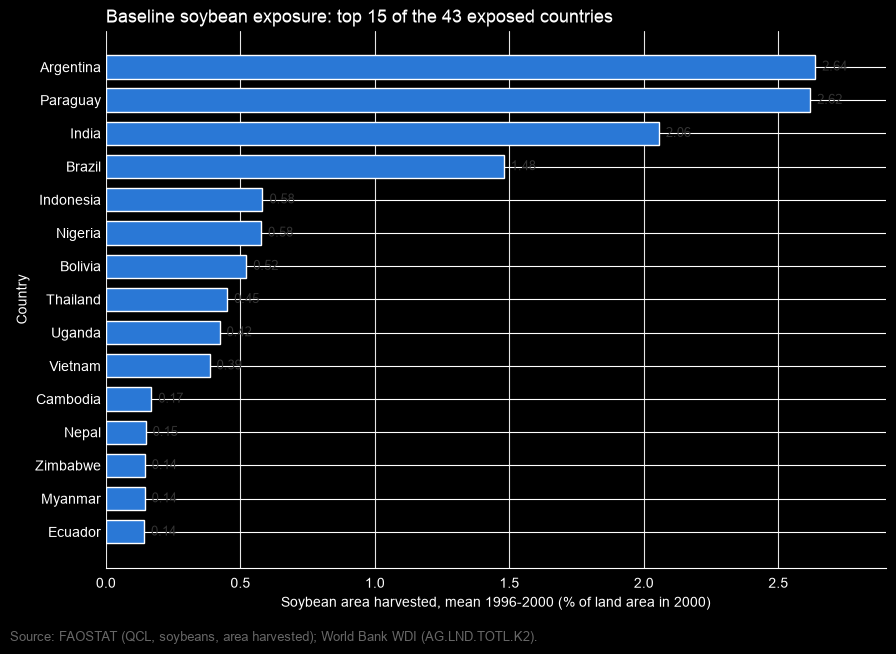

In [9]:
# Top 15 countries by baseline exposure
top = exposure.nlargest(15, "exposure_soy").sort_values("exposure_soy")
values = top["exposure_soy"] * 100

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top["country"], values, color="#2a78d6", height=0.7)
for y, value in enumerate(values):
    ax.text(value + values.max() * 0.01, y, f"{value:.2f}", va="center", fontsize=9, color="#333333")

ax.set_title(f"Baseline soybean exposure: top 15 of the {n_exposed} exposed countries",
             loc="left", fontsize=13)
ax.set_xlabel("Soybean area harvested, mean 1996-2000 (% of land area in 2000)")
ax.set_ylabel("Country")
ax.set_xlim(0, values.max() * 1.1)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.text(0.01, 0.005, "Source: FAOSTAT (QCL, soybeans, area harvested); World Bank WDI (AG.LND.TOTL.K2).",
         fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "soy_exposure_top15.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
# Consistency of the two soy sources and quality of the FAOSTAT figures
total_defor = df.groupby("iso3", as_index=False)["defor_ha"].sum().rename(columns={"defor_ha": "soy_defor_2001_2023_ha"})
check = exposure.merge(total_defor, on="iso3")

zero_with_defor = check[check["exposure_soy"].eq(0) & check["soy_defor_2001_2023_ha"].gt(0)]
print("Exposure 0 but positive DeDuCE soybean deforestation:", len(zero_with_defor))
print(zero_with_defor[["country", "region", "soy_defor_2001_2023_ha"]]
      .sort_values("soy_defor_2001_2023_ha", ascending=False).to_string(index=False))
print("Their share of sample soybean deforestation:",
      round(zero_with_defor["soy_defor_2001_2023_ha"].sum() / check["soy_defor_2001_2023_ha"].sum(), 4))

official = fao.assign(official=fao["Flag"].eq("A")).groupby("country")["official"].sum()
print(top.sort_values("exposure_soy", ascending=False).assign(
    exposure_pct=lambda d: (d["exposure_soy"] * 100).round(3),
    official_years_of_5=lambda d: d["country"].map(official).astype(int),
)[["country", "region", "area_1996_2000_ha", "exposure_pct", "official_years_of_5"]].to_string(index=False))

Exposure 0 but positive DeDuCE soybean deforestation: 5
   country                    region  soy_defor_2001_2023_ha
     Ghana                    Africa            26772.238116
    Malawi                    Africa            21655.376880
Mozambique                    Africa             8996.359940
Bangladesh              Asia-Pacific               85.684884
      Cuba Latin America & Caribbean               10.525221
Their share of sample soybean deforestation: 0.0092
  country                    region  area_1996_2000_ha  exposure_pct  official_years_of_5
Argentina Latin America & Caribbean          7215763.6         2.637                    5
 Paraguay Latin America & Caribbean          1040181.6         2.618                    5
    India              Asia-Pacific          6111140.0         2.055                    5
   Brazil Latin America & Caribbean         12361557.0         1.479                    5
Indonesia              Asia-Pacific          1092703.6         0.582        

## 3. Main regression

In [11]:
from linearmodels.panel import PanelOLS

# Log real prices by year, lags and leads are built on a continuous annual index
PRICE_SERIES = {"Soybeans": "soy", "Crude oil, average": "crude", "Wheat, US HRW": "wheat"}
wide = (prices[prices["commodity"].isin(PRICE_SERIES)]
        .pivot(index="year", columns="commodity", values="log_price_real")
        .rename(columns=PRICE_SERIES))
assert wide.index.is_monotonic_increasing and (np.diff(wide.index) == 1).all()

price_terms = pd.DataFrame({
    "p_soy_l1": wide["soy"].shift(1),
    "p_soy_l2": wide["soy"].shift(2),
    "p_soy_l3": wide["soy"].shift(3),
    "p_soy_f1": wide["soy"].shift(-1),
    "p_crude_l1": wide["crude"].shift(1),
    "p_wheat_l1": wide["wheat"].shift(1),
}).reset_index()

reg = (df.merge(exposure[["iso3", "exposure_soy"]], on="iso3", validate="many_to_one")
         .merge(price_terms, on="year", validate="many_to_one"))
assert len(reg) == 1426

for term in ["soy_l1", "soy_l2", "soy_l3", "soy_f1", "crude_l1", "wheat_l1"]:
    reg["x_" + term] = reg["exposure_soy"] * reg["p_" + term]

assert np.isfinite(reg.filter(like="x_")).all().all()
assert np.isfinite(reg["log_agri_loss_rate"]).all()

reg["region_year"] = pd.factorize(reg["region"] + reg["year"].astype(str))[0]
reg = reg.set_index(["iso3", "year"]).sort_index()

In [12]:
def fit(data, y, xs, region_year=False):
    """Fixed effects regression with standard errors clustered by country."""
    if region_year:
        model = PanelOLS(data[y], data[xs], entity_effects=True, other_effects=data[["region_year"]])
    else:
        model = PanelOLS(data[y], data[xs], entity_effects=True, time_effects=True)
    return model.fit(cov_type="clustered", cluster_entity=True)


def tidy(res, spec, terms, group):
    """One row per reported coefficient."""
    ci = res.conf_int()
    return pd.DataFrame([{
        "group": group, "specification": spec, "term": t, "coef": res.params[t], "se": res.std_errors[t],
        "p_value": res.pvalues[t], "ci_low": ci.loc[t, "lower"], "ci_high": ci.loc[t, "upper"],
        "n": int(res.nobs),
    } for t in terms])


Y = "y_soy_asinh"
L1, L2, L3 = "x_soy_l1", "x_soy_l2", "x_soy_l3"

main = fit(reg, Y, [L1])
lags = pd.concat([
    tidy(main, "Main: price t-1", [L1], "Main and lags"),
    tidy(fit(reg, Y, [L2]), "Price t-2 alone", [L2], "Main and lags"),
    tidy(fit(reg, Y, [L3]), "Price t-3 alone", [L3], "Main and lags"),
    tidy(fit(reg, Y, [L1, L2, L3]), "Lags 1-3 together", [L1, L2, L3], "Main and lags"),
], ignore_index=True)
lags.drop(columns="group").round(4)

,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Main: price t-1,x_soy_l1,-2.8421,0.9711,0.0035,-4.7473,-0.9370,1426
1,Price t-2 alone,x_soy_l2,-3.7550,1.3696,0.0062,-6.4418,-1.0682,1426
2,Price t-3 alone,x_soy_l3,-3.5020,1.3611,0.0102,-6.1721,-0.8318,1426
3,Lags 1-3 together,x_soy_l1,1.5058,0.9836,0.1260,-0.4238,3.4353,1426
4,Lags 1-3 together,x_soy_l2,-4.6005,1.7771,0.0097,-8.0867,-1.1143,1426
5,Lags 1-3 together,x_soy_l3,-0.5064,0.5691,0.3738,-1.6229,0.6101,1426


In [13]:
# Size of the main estimate: effect of a 10% higher price in t-1, in points of the outcome
beta = main.params[L1]
dlog = np.log(1.10)
producers = exposure[exposure["exposure_soy"] > 0]
reference = pd.Series({
    "Brazil": exposure.set_index("country").loc["Brazil", "exposure_soy"],
    "Paraguay": exposure.set_index("country").loc["Paraguay", "exposure_soy"],
    "Argentina": exposure.set_index("country").loc["Argentina", "exposure_soy"],
    "Median producer": producers["exposure_soy"].median(),
})
pd.DataFrame({"exposure_pct": reference * 100, "effect_of_10pct_price": beta * reference * dlog}).round(5)

,exposure_pct,effect_of_10pct_price
Brazil,1.47898,-0.00401
Paraguay,2.61813,-0.00709
Argentina,2.63668,-0.00714
Median producer,0.02545,-0.00007


## 4. Event study

In [14]:
# Exposure x year dummies, 2001 is the reference year
YEARS = list(range(START_YEAR + 1, END_YEAR + 1))
year_index = reg.index.get_level_values("year")
for y in YEARS:
    reg[f"ex_{y}"] = reg["exposure_soy"] * (year_index == y).astype(float)

event = fit(reg, Y, [f"ex_{y}" for y in YEARS])
ci = event.conf_int()
es = pd.DataFrame({
    "year": YEARS,
    "coef": [event.params[f"ex_{y}"] for y in YEARS],
    "ci_low": [ci.loc[f"ex_{y}", "lower"] for y in YEARS],
    "ci_high": [ci.loc[f"ex_{y}", "upper"] for y in YEARS],
}).merge(price_terms[["year", "p_soy_l1"]], on="year")

es_full = pd.concat([pd.DataFrame({"year": [START_YEAR], "coef": [0.0], "ci_low": [0.0], "ci_high": [0.0],
                                   "p_soy_l1": price_terms.set_index("year").loc[START_YEAR, "p_soy_l1"]}), es])

print("Correlation of yearly coefficients with the t-1 soy price:", round(es["coef"].corr(es["p_soy_l1"]), 3))
print("Years whose 95% CI excludes 0:", es.loc[(es["ci_low"] > 0) | (es["ci_high"] < 0), "year"].tolist())
es.round(4)

Correlation of yearly coefficients with the t-1 soy price: -0.424
Years whose 95% CI excludes 0: [2003, 2004, 2012, 2015, 2016, 2017, 2018, 2019, 2023]


,year,coef,ci_low,ci_high,p_soy_l1
0,2002,0.3878,-0.7455,1.5211,5.5452
1,2003,2.1623,0.7815,3.5431,5.6384
2,2004,4.6630,0.9083,8.4177,5.8051
3,2005,2.3851,-0.8508,5.6210,5.8861
4,2006,1.5399,-1.7329,4.8126,5.7462
5,2007,1.7190,-0.7997,4.2378,5.7004
6,2008,3.6495,-2.1424,9.4413,5.9940
7,2009,-0.1681,-1.2796,0.9433,6.2305
8,2010,1.3061,-0.8784,3.4906,6.0845
9,2011,3.9198,-0.8188,8.6583,6.1026


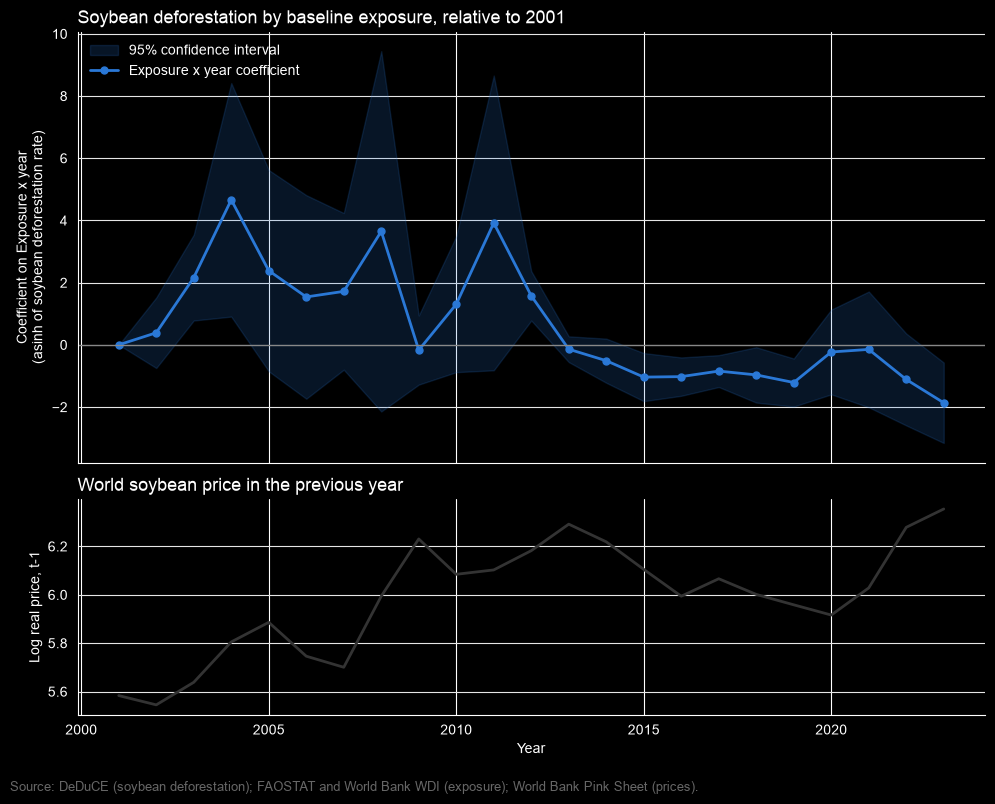

In [15]:
SOURCE = ("Source: DeDuCE (soybean deforestation); FAOSTAT and World Bank WDI (exposure); "
          "World Bank Pink Sheet (prices).")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

ax1.fill_between(es_full["year"], es_full["ci_low"], es_full["ci_high"], color="#2a78d6", alpha=0.18, label="95% confidence interval")
ax1.plot(es_full["year"], es_full["coef"], color="#2a78d6", linewidth=2, marker="o", markersize=5, label="Exposure x year coefficient")
ax1.axhline(0, color="#888888", linewidth=0.9)
ax1.set_title("Soybean deforestation by baseline exposure, relative to 2001", loc="left", fontsize=13)
ax1.set_ylabel("Coefficient on Exposure x year\n(asinh of soybean deforestation rate)")
ax1.legend(frameon=False, loc="upper left")

ax2.plot(es_full["year"], es_full["p_soy_l1"], color="#333333", linewidth=2)
ax2.set_title("World soybean price in the previous year", loc="left", fontsize=13)
ax2.set_ylabel("Log real price, t-1")
ax2.set_xlabel("Year")

for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, 0.005, SOURCE, fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 1))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "soy_event_study.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Placebos

In [16]:
placebos = pd.concat([
    tidy(fit(reg, Y, ["x_soy_f1"]), "Placebo: price t+1", ["x_soy_f1"], "Placebos"),
    tidy(fit(reg, Y, ["x_wheat_l1"]), "Placebo: wheat price t-1", ["x_wheat_l1"], "Placebos"),
], ignore_index=True)
placebos.drop(columns="group").round(4)

,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Placebo: price t+1,x_soy_f1,-0.8712,0.4479,0.0520,-1.7499,0.0074,1426
1,Placebo: wheat price t-1,x_wheat_l1,-1.7364,0.5638,0.0021,-2.8424,-0.6304,1426


## 6. Robustness

In [17]:
# Exposure bins: above and below the median among producers, non-producers are the reference
median_exposure = reg.loc[reg["exposure_soy"] > 0, "exposure_soy"].median()
reg["x_high"] = (reg["exposure_soy"] > median_exposure).astype(float) * reg["p_soy_l1"]
reg["x_low"] = (reg["exposure_soy"].between(0, median_exposure, inclusive="right")).astype(float) * reg["p_soy_l1"]

no_top2 = reg[~reg.index.get_level_values("iso3").isin(["ARG", "BRA"])]
assert no_top2.index.get_level_values("iso3").nunique() == 60

robust = pd.concat([
    tidy(fit(no_top2, Y, [L1]), "Without Argentina and Brazil", [L1], "Robustness"),
    tidy(fit(reg, Y, [L1, "x_crude_l1"]), "Crude oil control", [L1], "Robustness"),
    tidy(fit(reg, Y, [L1], region_year=True), "Region x year FE", [L1], "Robustness"),
    tidy(fit(reg, "y_soy_log1p", [L1]), "log(1 + rate) outcome", [L1], "Robustness"),
], ignore_index=True)

other_units = pd.concat([
    tidy(fit(reg, "log_agri_loss_rate", [L1]), "GFW agricultural loss (log rate)", [L1], "Other units"),
    tidy(fit(reg, Y, ["x_high", "x_low"]), "Binned exposure", ["x_high", "x_low"], "Other units"),
], ignore_index=True)

print("Median exposure among producers (share of land):", round(median_exposure, 6))
pd.concat([robust, other_units], ignore_index=True).drop(columns="group").round(4)

Median exposure among producers (share of land): 0.000254


,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Without Argentina and Brazil,x_soy_l1,-1.6687,1.1787,0.1571,-3.9811,0.6437,1380
1,Crude oil control,x_soy_l1,-4.0348,2.5339,0.1116,-9.0057,0.9362,1426
2,Region x year FE,x_soy_l1,-2.6880,0.9839,0.0064,-4.6181,-0.7579,1426
3,log(1 + rate) outcome,x_soy_l1,-2.6229,0.8877,0.0032,-4.3642,-0.8815,1426
4,GFW agricultural loss (log rate),x_soy_l1,-23.5551,11.1811,0.0353,-45.4894,-1.6207,1426
5,Binned exposure,x_high,-0.0149,0.0083,0.0724,-0.0311,0.0014,1426
6,Binned exposure,x_low,-0.0010,0.0040,0.8100,-0.0088,0.0069,1426


## 7. Summary of specifications

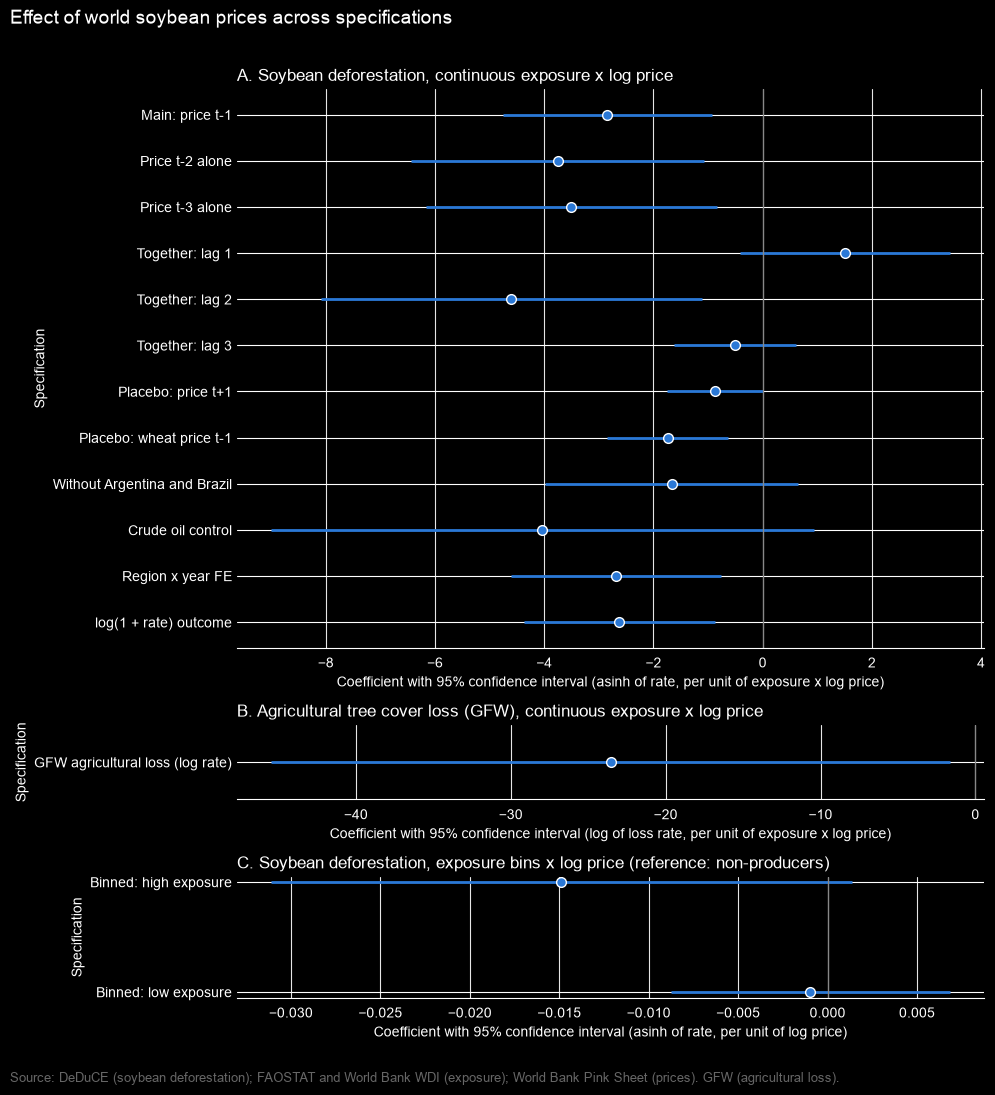

In [18]:
# Panel A: same outcome scale and same continuous exposure. Panels B and C have their own units.
same_scale = pd.concat([lags, placebos, robust], ignore_index=True)
same_scale["label"] = same_scale["specification"]
joint = same_scale["specification"].eq("Lags 1-3 together")
same_scale.loc[joint, "label"] = "Together: " + same_scale.loc[joint, "term"].map({L1: "lag 1", L2: "lag 2", L3: "lag 3"})

other = other_units.copy()
other["label"] = other["specification"]
binned = other["specification"].eq("Binned exposure")
other.loc[binned, "label"] = other.loc[binned, "term"].map({"x_high": "Binned: high exposure", "x_low": "Binned: low exposure"})


def coef_panel(ax, table, title):
    table = table.iloc[::-1].reset_index(drop=True)
    ax.hlines(table.index, table["ci_low"], table["ci_high"], color="#2a78d6", linewidth=2)
    ax.plot(table["coef"], table.index, "o", color="#2a78d6", markersize=7, markeredgecolor="white")
    ax.axvline(0, color="#888888", linewidth=0.9)
    ax.set_yticks(table.index, table["label"])
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylabel("Specification")
    ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)


gfw = other[other["specification"].str.startswith("GFW")]
bins = other[other["specification"].eq("Binned exposure")]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 11), gridspec_kw={"height_ratios": [len(same_scale), 1.6, 2.6]})
coef_panel(ax1, same_scale, "A. Soybean deforestation, continuous exposure x log price")
ax1.set_xlabel("Coefficient with 95% confidence interval (asinh of rate, per unit of exposure x log price)")
coef_panel(ax2, gfw, "B. Agricultural tree cover loss (GFW), continuous exposure x log price")
ax2.set_xlabel("Coefficient with 95% confidence interval (log of loss rate, per unit of exposure x log price)")
coef_panel(ax3, bins, "C. Soybean deforestation, exposure bins x log price (reference: non-producers)")
ax3.set_xlabel("Coefficient with 95% confidence interval (asinh of rate, per unit of log price)")

fig.suptitle("Effect of world soybean prices across specifications", x=0.01, ha="left", fontsize=14)
fig.text(0.01, 0.005, SOURCE + " GFW (agricultural loss).", fontsize=9, color="#666666")
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
if os.path.isdir(FIGURES):
    fig.savefig(FIGURES + "soy_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Additional checks (added after the main analysis, not in the initial plan)

In [19]:
# Co-movement of the world prices over the estimation period (t-1 prices)
period = price_terms[price_terms["year"].between(START_YEAR, END_YEAR)]
print(period[["p_soy_l1", "p_wheat_l1", "p_crude_l1"]].corr().round(2).to_string())

# Exposure x linear trend absorbs a smooth divergence of exposed countries
reg["x_trend"] = reg["exposure_soy"] * (reg.index.get_level_values("year") - START_YEAR)

W, C, TR = "x_wheat_l1", "x_crude_l1", "x_trend"
extra = pd.concat([
    tidy(fit(reg, Y, [L1, W]), "Soy and wheat together", [L1, W], "Co-movement"),
    tidy(fit(reg, Y, [L1, W, C]), "Soy, wheat and crude together", [L1, W, C], "Co-movement"),
    tidy(fit(reg, Y, [L1, TR]), "Main + exposure trend", [L1, TR], "Trend"),
    tidy(fit(reg, Y, [W, TR]), "Wheat placebo + exposure trend", [W, TR], "Trend"),
    tidy(fit(reg, Y, [L1, W, C, TR]), "Soy, wheat, crude + exposure trend", [L1, W, C, TR], "Trend"),
], ignore_index=True)
extra.drop(columns="group").round(4)

            p_soy_l1  p_wheat_l1  p_crude_l1
p_soy_l1        1.00        0.84        0.75
p_wheat_l1      0.84        1.00        0.78
p_crude_l1      0.75        0.78        1.00


,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Soy and wheat together,x_soy_l1,-4.6290,1.7244,0.0074,-8.0118,-1.2461,1426
1,Soy and wheat together,x_wheat_l1,2.0676,0.9101,0.0233,0.2822,3.8530,1426
2,"Soy, wheat and crude together",x_soy_l1,-4.9677,2.3845,0.0374,-9.6454,-0.2900,1426
3,"Soy, wheat and crude together",x_wheat_l1,1.5550,0.7700,0.0436,0.0445,3.0656,1426
4,"Soy, wheat and crude together",x_crude_l1,0.6631,1.6525,0.6883,-2.5787,3.9050,1426
5,Main + exposure trend,x_soy_l1,1.4804,1.9203,0.4409,-2.2867,5.2476,1426
6,Main + exposure trend,x_trend,-0.2107,0.1297,0.1046,-0.4652,0.0438,1426
7,Wheat placebo + exposure trend,x_wheat_l1,0.9748,1.0825,0.3680,-1.1489,3.0984,1426
8,Wheat placebo + exposure trend,x_trend,-0.1922,0.1041,0.0650,-0.3963,0.0120,1426
9,"Soy, wheat, crude + exposure trend",x_soy_l1,1.5203,1.4883,0.3072,-1.3994,4.4400,1426


In [20]:
# Sensitivity to the most influential countries
def without(codes):
    return reg[~reg.index.get_level_values("iso3").isin(codes)]


DROPS = {
    "Without Brazil": ["BRA"],
    "Without Argentina": ["ARG"],
    "Without Paraguay": ["PRY"],
    "Without Brazil, Argentina, Paraguay": ["BRA", "ARG", "PRY"],
}
influence = pd.concat([tidy(fit(without(c), Y, [L1]), name, [L1], "Influence") for name, c in DROPS.items()],
                      ignore_index=True)
influence.drop(columns="group").round(4)

,specification,term,coef,se,p_value,ci_low,ci_high,n
0,Without Brazil,x_soy_l1,-2.8604,1.0685,0.0075,-4.9566,-0.7642,1403
1,Without Argentina,x_soy_l1,-1.8085,0.9908,0.0682,-3.7522,0.1353,1403
2,Without Paraguay,x_soy_l1,-2.6108,1.4573,0.0734,-5.4696,0.2481,1403
3,"Without Brazil, Argentina, Paraguay",x_soy_l1,0.3900,0.4094,0.3410,-0.4133,1.1932,1357


In [21]:
def wild_cluster_p(data, y, x, draws=9999, seed=2026):
    """Restricted wild cluster bootstrap (Rademacher) for one regressor with country and year FE."""
    Y_mat = data[y].unstack("year").to_numpy()
    X_mat = data[x].unstack("year").to_numpy()
    assert not (np.isnan(Y_mat).any() or np.isnan(X_mat).any())  # balanced panel

    def within(a):
        return a - a.mean(1, keepdims=True) - a.mean(0, keepdims=True) + a.mean()

    y_w, x_w = within(Y_mat), within(X_mat)
    n_g = y_w.shape[0]
    h = (x_w ** 2).sum(1)
    s = (x_w * y_w).sum(1)
    H = h.sum()

    beta = s.sum() / H
    t_obs = beta / (np.sqrt(((s - beta * h) ** 2).sum()) / H)

    # Under the null the residuals are the demeaned outcome; year means are re-absorbed in each draw
    w = np.random.default_rng(seed).choice([-1.0, 1.0], size=(draws, n_g))
    beta_star = (w * s).sum(1) / H
    scores = w * s - (w @ y_w / n_g) @ x_w.T - beta_star[:, None] * h
    t_star = beta_star / (np.sqrt((scores ** 2).sum(1)) / H)
    return beta, t_obs, float((np.abs(t_star) >= abs(t_obs)).mean())


cases = {
    "Main: price t-1": (reg, L1),
    "Without Brazil": (without(["BRA"]), L1),
    "Without Argentina and Brazil": (without(["ARG", "BRA"]), L1),
    "Without Brazil, Argentina, Paraguay": (without(["BRA", "ARG", "PRY"]), L1),
    "Placebo: wheat price t-1": (reg, W),
    "Placebo: price t+1": (reg, "x_soy_f1"),
}
rows = []
for name, (data, x) in cases.items():
    beta, t_obs, p_boot = wild_cluster_p(data, Y, x)
    res = fit(data, Y, [x])
    assert np.isclose(beta, res.params[x])
    rows.append({"specification": name, "coef": beta, "clustered_p": res.pvalues[x], "wild_bootstrap_p": p_boot,
                 "countries": data.index.get_level_values("iso3").nunique()})
pd.DataFrame(rows).round(4)

,specification,coef,clustered_p,wild_bootstrap_p,countries
0,Main: price t-1,-2.8421,0.0035,0.1648,62
1,Without Brazil,-2.8604,0.0075,0.3449,61
2,Without Argentina and Brazil,-1.6687,0.1571,0.7804,60
3,"Without Brazil, Argentina, Paraguay",0.3900,0.3410,0.3881,59
4,Placebo: wheat price t-1,-1.7364,0.0021,0.1682,62
5,Placebo: price t+1,-0.8712,0.0520,0.3224,62
